# Imports

In [1]:
import os
os.environ['KERAS_BACKEND'] = 'torch'

import math
import datasets
import numpy as np
import transformers
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import train_test_split
import tqdm.notebook as tqdm
import sklearn.model_selection
import matplotlib.pyplot as plt
import keras
import pandas as pd

# Dataset

Load the dataset (we will be using [go_emotions](https://huggingface.co/datasets/google-research-datasets/go_emotions)). Pretokenize data or make a loader that tokenizes the sentenses as you iterate through the dataset. Implement two datasets: variable and fixed sentence length (in tokens). Don't forget to split the dataset into train and test subsets

In [2]:
dataset = datasets.load_dataset('google-research-datasets/go_emotions', name='raw', split='train', cache_dir='dataset').to_pandas()

In [3]:
emotions = [
    'admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity',
    'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear',
    'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief',
    'remorse', 'sadness', 'surprise', 'neutral'
]

In [4]:
dataset = dataset[['text', *emotions]]

In [5]:
dataset[dataset['text'] == 'That game hurt.']

,text,admiration,amusement,anger,annoyance,approval,caring,confusion,curiosity,desire,...,love,nervousness,optimism,pride,realization,relief,remorse,sadness,surprise,neutral
0,That game hurt.,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
11947,That game hurt.,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
45274,That game hurt.,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
129293,That game hurt.,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
156312,That game hurt.,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


In [6]:
agg_emotions = dataset.groupby(by='text')[emotions].sum()
agg_emotions = (agg_emotions >= 2).astype(int)
agg_emotions.head()

,admiration,amusement,anger,annoyance,approval,caring,confusion,curiosity,desire,disappointment,...,love,nervousness,optimism,pride,realization,relief,remorse,sadness,surprise,neutral
text,,,,,,,,,,,,,,,,,,,,,
"""If you don't wear BROWN AND ORANGE...YOU DON'T MATTER!"" We need a tshirt with that on it asap!",0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
"""What do Scottish people look like?"" How I would love to have been there to take a swing at that softball.",0,0,0,0,0,0,0,1,0,0,...,1,0,0,0,0,0,0,0,0,0
"### A surprise, to be sure, but a welcome one",0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
"'*Pray*, v. To ask that the laws of the universe be annulled in behalf of a single petitioner, confessedly unworthy.' — [NAME]",0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
">it'll get invaded by tankie, unfortunately. How apropos.",0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


In [7]:
tokenizer = transformers.AutoTokenizer.from_pretrained('gpt2', cache_dir='../gpt2_tokenizer')
tokenizer.pad_token = tokenizer.eos_token

In [8]:
agg_emotions.iloc[agg_emotions[emotions].sum(axis=1).argmax()]

admiration        0
amusement         0
anger             0
annoyance         0
approval          1
caring            0
confusion         0
curiosity         0
desire            0
disappointment    0
disapproval       0
disgust           0
embarrassment     0
excitement        1
fear              0
gratitude         0
grief             0
joy               1
love              0
nervousness       0
optimism          1
pride             0
realization       0
relief            0
remorse           0
sadness           0
surprise          1
neutral           0
Name: A surprise to be sure, but a welcome one., dtype: int64

In [9]:
X = list(agg_emotions.index)
y = agg_emotions[emotions].to_numpy()
X_tokenized = [tokenizer.encode(e) for e in X]
X_lens = np.array(list(map(len, X_tokenized)))

X_train, X_val, y_train, y_val = train_test_split(
    X_tokenized, y, test_size=0.2, random_state=1, shuffle=True,
)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1435 > 1024). Running this sequence through the model will result in indexing errors


In [10]:
X_lens_argsort = np.argsort(X_lens)

In [11]:
X_lens[X_lens_argsort][-70:]

array([  43,   43,   43,   43,   43,   44,   44,   44,   44,   44,   44,
         44,   44,   44,   44,   45,   45,   45,   45,   45,   45,   45,
         46,   46,   46,   46,   46,   46,   46,   46,   46,   46,   47,
         47,   47,   48,   48,   48,   48,   48,   49,   49,   51,   51,
         51,   52,   54,   54,   55,   55,   56,   58,   59,   59,   63,
         63,   65,   67,   67,   71,   85,   93,   95,  104,  165,  175,
        184,  209,  318, 1435])

Text(0.5, 0, 'Длинна текста в токенах')

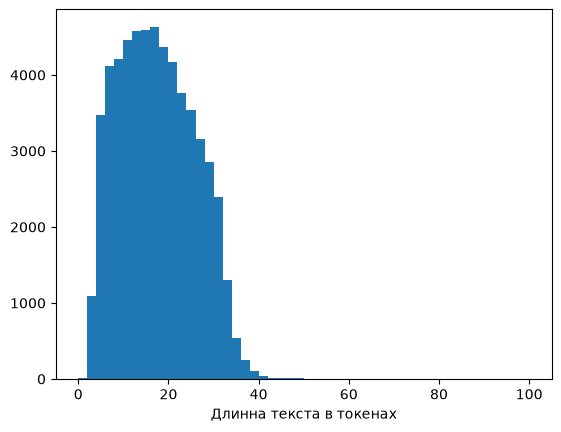

In [12]:
plt.hist(X_lens, bins=50, range=(0, 100))
plt.xlabel('Длинна текста в токенах')

In [13]:
b_size = 512
X_lens_bins = np.array_split(X_lens[X_lens_argsort], -(-len(X_lens) // b_size))
y_bins = np.array_split(y[X_lens_argsort], -(-len(X_lens) // b_size))
X_lens_bins

[array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
        3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
        3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
        3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
        3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
        3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
        3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
        3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
        3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
        3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
        3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 

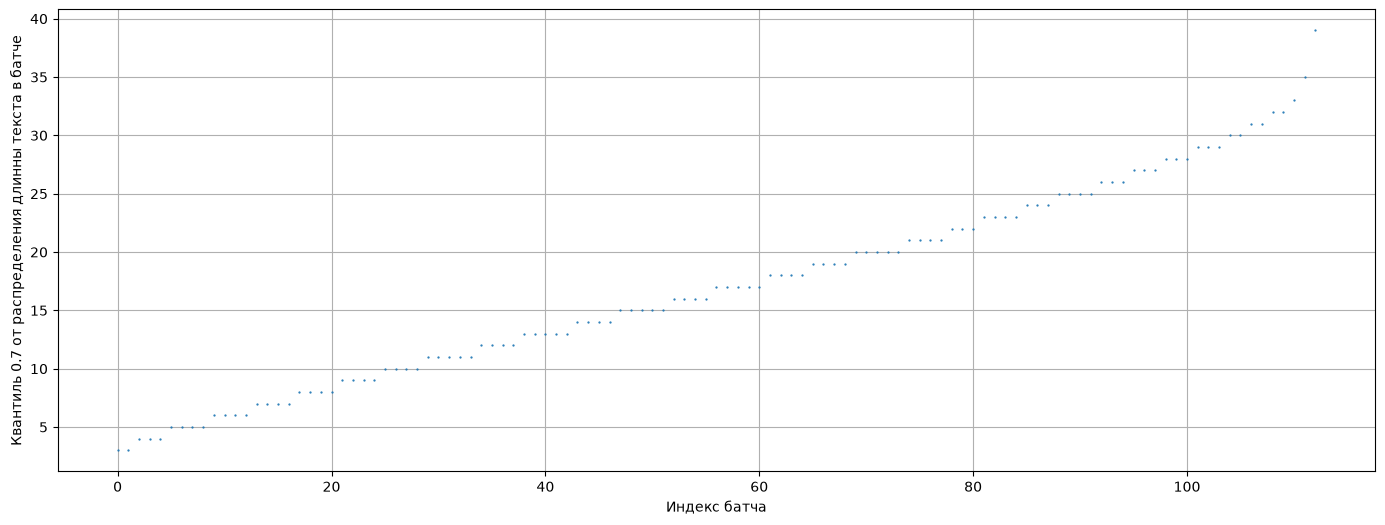

In [14]:
q = 0.7

plt.figure(figsize=(17, 6))
plt.plot([np.quantile(e, q) for e in X_lens_bins], linestyle=' ', marker='o', markersize=0.6)
plt.xlabel('Индекс батча')
plt.ylabel(f'Квантиль {q} от распределения длинны текста в батче')
plt.grid()

In [15]:
y_bins_sum = [b.sum(axis=0) for b in y_bins]
y_bins_sum

[array([ 71,  15,  15,  18,  22,  11,   8,  14,   1,   4,   9,  10,   0,
         21,   7,  58,   0,  13,  15,   0,   5,   0,   2,   0,   3,   9,
         10, 214]),
 array([ 73,  20,  41,  12,  27,   5,   5,   7,   1,   5,   7,   4,   4,
          9,   9,  27,   3,  16,  26,   0,   6,   4,   1,   0,   4,  17,
          8, 220]),
 array([ 76,  23,  29,  22,  16,  16,   8,  13,   0,   4,  10,  11,   2,
         11,   6,  55,   1,  13,  20,   3,   6,   2,   1,   1,   2,  20,
          8, 173]),
 array([ 57,  22,  26,  22,  27,  11,   4,  13,   2,   6,  10,  13,   0,
         19,   5,  34,   1,  33,  26,   1,   7,   0,   7,   1,   1,  16,
         11, 180]),
 array([ 62,  25,  35,  16,  25,   8,  12,  22,   4,   7,  14,   7,   2,
          8,   4,  45,   0,  11,  32,   2,   4,   0,   6,   1,   3,  14,
          4, 193]),
 array([ 81,  31,  18,  25,  33,  16,   7,   8,   0,   4,  17,   4,   2,
          8,   4,  36,   5,  21,  23,   2,  16,   2,   2,   0,   5,  14,
          8, 157]),
 arr

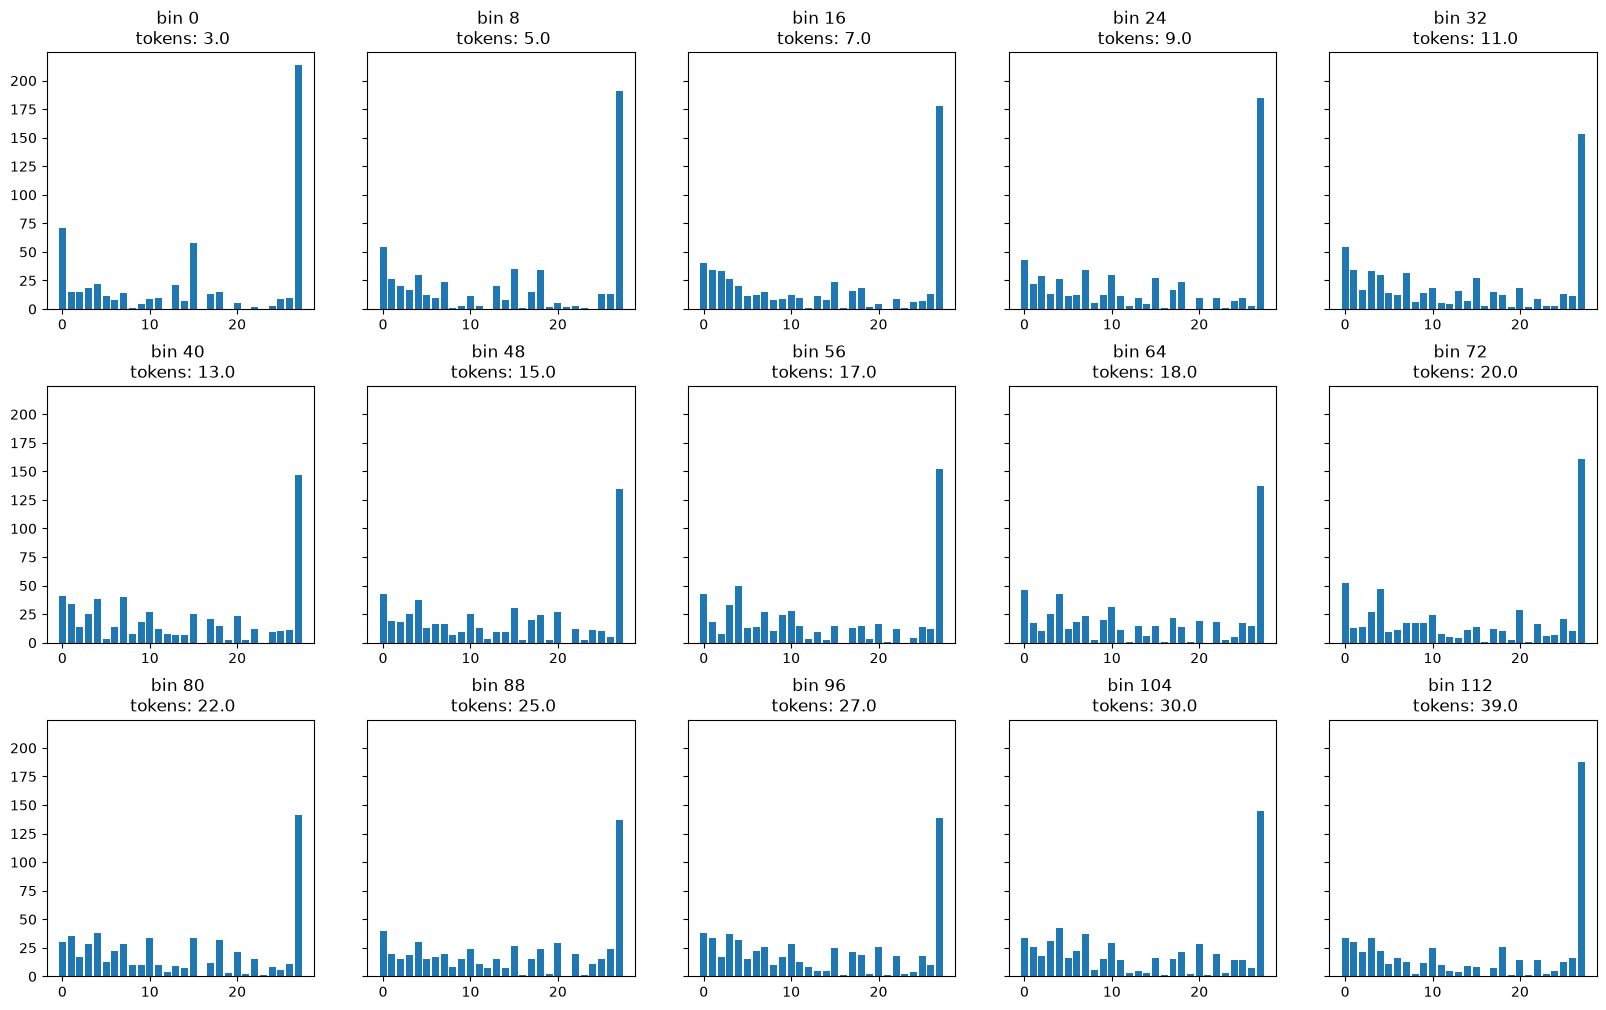

In [16]:
n_graphs = 15
n_cols = 5
q = 0.7
n_rows = int(np.ceil(n_graphs / n_cols))

fig, axes = plt.subplots(n_rows, n_cols,
                         figsize=(4 * n_cols, 4 * n_rows),
                         sharey=True, )
idx = np.linspace(0, len(y_bins_sum) - 1, n_graphs).round().astype(int)
axes = axes.flatten()

for ax, i in zip(axes, idx):
    ax.bar(range(len(emotions)), y_bins_sum[i])
    ax.set_title(f"bin {i} \n tokens: {np.quantile(X_lens_bins[i], q)}")
fig.subplots_adjust(hspace=0.3)

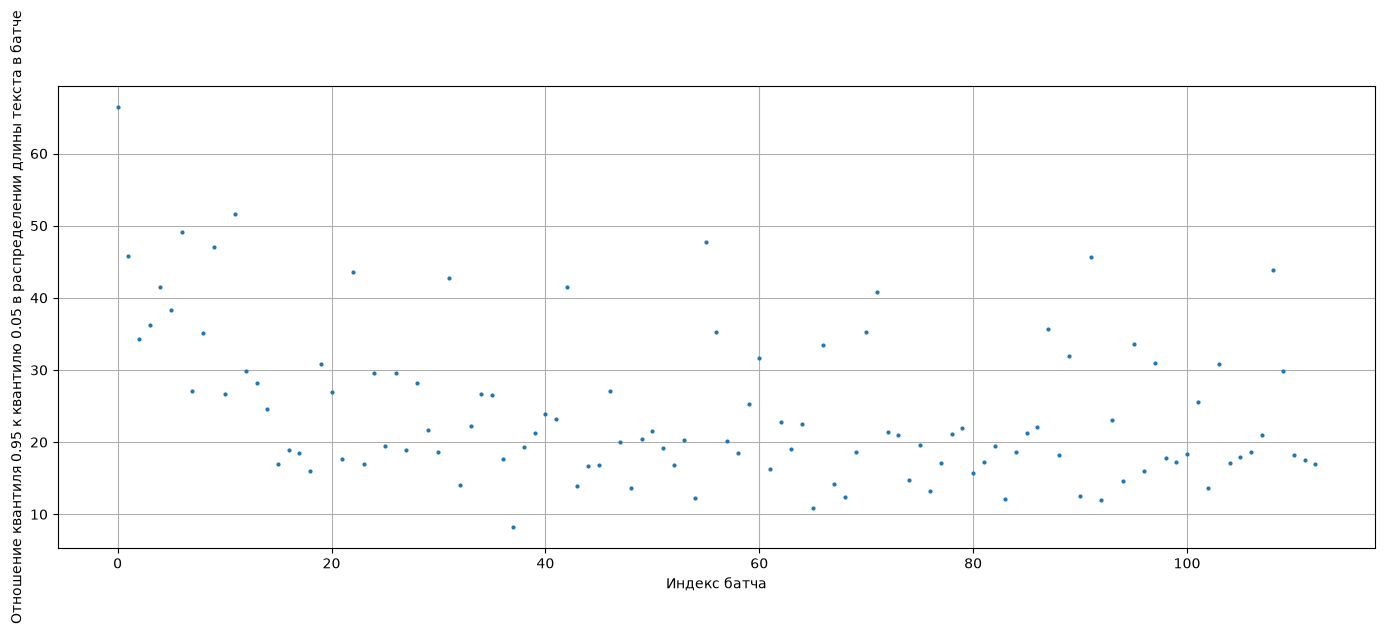

In [17]:
q = 0.95
y_bins_sum = [e.sum(axis=0) for e in y_bins]
y_bins_diff = [np.quantile(e, q) / (np.quantile(e, 1 - q) + 1) for e in y_bins_sum]

plt.figure(figsize=(17, 6))
plt.plot(y_bins_diff, linestyle=' ', marker='o', markersize=2)
plt.xlabel('Индекс батча')
plt.ylabel(f'Отношение квантиля {q:.2f} к квантилю {1 - q:.2f} в распределении длины текста в батче')
plt.grid()

In [18]:
class SmartBatchDataset(keras.utils.PyDataset):
    def __init__(self, X, y, batch_size=64, q=0.5, seed=1, shuffle=False, **kwargs):
        super().__init__(**kwargs)
        self.X = X
        self.y = y
        self.batch_size = batch_size
        self.q = q
        self.rng = np.random.default_rng(seed=seed)
        self.shuffle = shuffle

        X_lens = np.array(list(map(len, self.X)), dtype='int32')
        idx_sorted = np.argsort(X_lens)

        self.X = [self.X[i] for i in idx_sorted]
        self.y = [self.y[i] for i in idx_sorted]
        X_lens = X_lens[idx_sorted]

        self.X = [self.X[i * batch_size: (i + 1) * batch_size] for i in range(-(-len(self.X) // batch_size))]
        self.y = [np.array(self.y[i * batch_size: (i + 1) * batch_size]) for i in range(-(-len(self.y) // batch_size))]
        X_lens = [X_lens[i * batch_size: (i + 1) * batch_size] for i in range(-(-len(X_lens) // batch_size))]

        for i in range(len(self.X)):            
            self.X[i] = keras.utils.pad_sequences(
                self.X[i], 
                maxlen=math.ceil(np.quantile(X_lens[i], self.q)),
                padding='post',
                truncating='post',
                value=tokenizer.pad_token_id
            )

        self.shuffle_batch_idx = np.arange(len(self.X))

        self.on_epoch_end()

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return (
            self.X[self.shuffle_batch_idx[idx]], 
            self.y[self.shuffle_batch_idx[idx]]
        )

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.shuffle_batch_idx)

In [19]:
class DefaultBatchDataset(keras.utils.PyDataset):
    def __init__(self, X, y, batch_size=64, q=0.5, seed=1, shuffle=False, **kwargs):
        super().__init__(**kwargs)
        self.X = X
        self.y = np.array(y)
        self.batch_size = batch_size
        self.q = q
        self.rng = np.random.default_rng(seed=seed)
        self.shuffle = shuffle

        self.X_lens = np.array(list(map(len, self.X)), dtype='int32')

        self.idxs = np.arange(len(self.X))

    def __len__(self):
        return -(-len(self.X) // self.batch_size)

    def __getitem__(self, idx):
        ind = self.idxs[idx * self.batch_size: (idx + 1) * self.batch_size]
        return keras.utils.pad_sequences(
            [self.X[i] for i in ind], 
            maxlen=math.ceil(np.quantile(self.X_lens[ind], self.q)),
            padding='post',
            truncating='post',
            value=tokenizer.pad_token_id
        ), self.y[ind]

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.idxs)


In [20]:
class FixedBatchDataset(keras.utils.PyDataset):
    def __init__(self, X, y, batch_size=64, seq_size=30, seed=1, shuffle=False, **kwargs):
        super().__init__(**kwargs)
        self.X = keras.utils.pad_sequences(
            X, 
            maxlen=seq_size,
            padding='post',
            truncating='post',
            value=tokenizer.pad_token_id
        )
        self.y = np.array(y)
        self.batch_size = batch_size
        self.seq_size = seq_size
        self.rng = np.random.default_rng(seed=seed)
        self.shuffle = shuffle

        self.idxs = np.arange(len(self.X))

    def __len__(self):
        return -(-len(self.X) // self.batch_size)

    def __getitem__(self, idx):
        ind = self.idxs[idx * self.batch_size: (idx + 1) * self.batch_size]
        return self.X[ind], self.y[ind]

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.idxs)

# Model

Implement your model. The model should have the RNN architecture (with LSTM or GRU cells), support stacking and bidirectional feature extraction.

In [21]:
def get_name(prefix: str | None = None, suffix: str | None = None, separator: str = '_') -> str | None:
    return prefix and prefix + separator + suffix or suffix or None

In [22]:
def get_model(
    units: int,
    n_tokens: int,
    n_labels: int,
    n_stacks: int = 1,
    bidirectional: bool = False,
    name: str | None = None,
    cell_type: type[keras.layers.Layer] = keras.layers.LSTMCell,
    *,
    embed_size: int = 128
) -> keras.Model:
    '''Creates a model with RNN architecture for sequence multilabel classification.

    Arguments:
        units: dimensionality of RNN cells
        n_tokens: number of tokens in the tokenizer dictionary
        n_labels: number of labels to be predicted
        n_stacks: number of RNN cells in the stack (1 -- no stacking)
        bidirectional: whether or not the model is bidirectional
        name: the model name
        cell_type: type of a cell to use, either keras.layers.LSTMCell or keras.layers.GRUCell

    Returns:
        The model'''

    inputs = x = keras.layers.Input(shape=(None,), name='Input', dtype='int32')
    x = keras.layers.Embedding(n_tokens, embed_size, name='Embedding')(x)

    if not bidirectional:
        layers = [cell_type(units=units, dropout=0.2, recurrent_dropout=0.2) for _ in range(n_stacks)]
        stacked = keras.layers.StackedRNNCells(layers)
        x = keras.layers.RNN(stacked, name=f'{n_stacks}StackedRNN')(x)
    else:
        for i in range(n_stacks):
            is_not_last = i != n_stacks - 1
            layer = keras.layers.RNN(cell_type(units=units, dropout=0.2, recurrent_dropout=0.2), return_sequences=is_not_last)
            x = keras.layers.Bidirectional(layer, name=f'BiRNN_{i}')(x)

    output = keras.layers.Dense(n_labels, name='output')(x)
    
    return keras.models.Model(inputs=inputs, outputs=output, name=name)

# Training

Train several models on the two dataset variants. Use either of the cell types (LSTM or GRU)
* Simple RNN (no stacking, one direction)
* Stacked RNN (stacking, one direction)
* Bidirectional RNN (no stacking, bidirectional)
* Stacked Bidirectional RNN (stacking, bidirectional)

In [23]:
models = [
    get_model(
        units=128,
        n_tokens=len(tokenizer.get_vocab()),
        n_labels=len(emotions),
        name='GRU_model',
        bidirectional=i[1],
        n_stacks=i[0],
        cell_type=keras.layers.GRUCell,
        embed_size=128
    )
    for i in [(1, False), (2, False), (1, True), (2, True)] * 3
]

I0000 00:00:1792281507.887310    6119 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792281509.401100    6119 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [24]:
models[11].summary()

Model: "GRU_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input (InputLayer)              │ (None, None)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Embedding (Embedding)           │ (None, None, 128)      │     6,432,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BiRNN_0 (Bidirectional)         │ (None, None, 256)      │       198,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BiRNN_1 (Bidirectional)         │ (None, 256)            │       296,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 28)             │         7,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,934,684 (26.45 MB)

 Trainable params: 6,934,684 (26.45 MB)

 Non-trainable params: 0 (0.00 B)

Which loss should be used to multilabel classification? Which metrics?

In [25]:
@keras.saving.register_keras_serializable()
class WeightedBCE(keras.losses.Loss):
    def __init__(self, w, from_logits=True, name="weighted_bce", **kwargs):
        super().__init__(name=name, **kwargs)
        self.w = w
        self.from_logits = from_logits

    def call(self, y_true, y_pred):
        bce = keras.ops.binary_crossentropy(
            y_true, y_pred, from_logits=self.from_logits
        )

        w = keras.ops.convert_to_tensor(self.w, dtype=bce.dtype)
        w = keras.ops.reshape(w, (1, -1))
        w = keras.ops.where(
            keras.ops.equal(y_true, 1.0),
            w,
            keras.ops.ones_like(bce),
        )

        return keras.ops.mean(bce * w, axis=-1)

    def get_config(self):
        config = super().get_config()
        config.update({
            'w': self.w,
            'from_logits': self.from_logits,
        })
        return config

In [26]:
w = y.sum(axis=0)
w = 1 / w
w /= w.min()
w = np.clip(w, 1.0, 100.0)
w

array([  3.47065728,   6.13485477,   9.06128703,   5.72876978,
         4.81073753,  12.95036496,  10.61124402,   6.52759382,
        22.14981273,  11.21491783,   6.87941062,  17.54896142,
        47.43850267,  16.89714286,  23.25294889,   5.35688406,
       100.        ,   9.92837157,   6.96584217,  85.29807692,
         8.98784195, 100.        ,  12.82863341,  97.48351648,
        26.52017937,  10.95185185,  13.33984962,   1.        ])

In [48]:
class SigmoidAUC(keras.metrics.AUC):
    def update_state(self, y_true, y_pred, sample_weight=None):
        return super().update_state(y_true, keras.ops.sigmoid(y_pred), sample_weight)

class SigmoidF1(keras.metrics.F1Score):
    def update_state(self, y_true, y_pred, sample_weight=None):
        return super().update_state(y_true, keras.ops.sigmoid(y_pred), sample_weight)

In [27]:
for model in models:
    model.compile(
        loss=WeightedBCE(w, from_logits=True),
        optimizer=keras.optimizers.Adam(
            clipnorm=1.0
        ),
        metrics=[
            keras.metrics.AUC(multi_label=True, name='auc', num_labels=len(emotions)),
            keras.metrics.F1Score(average='macro', name='f1'),
        ]
    )

In [28]:
smart_dataset = SmartBatchDataset(X_train, y_train, batch_size=300, q=0.8, shuffle=True)
default_dataset = DefaultBatchDataset(X_train, y_train, batch_size=300, q=0.8, shuffle=True)
fixed_dataset = FixedBatchDataset(X_train, y_train, batch_size=300, seq_size=30, shuffle=True)

val_dataset = DefaultBatchDataset(X_val, y_val, batch_size=300, q=0.8, shuffle=False)

In [29]:
def make_callbacks(name):
    return [
        keras.callbacks.ModelCheckpoint(f'{name}.keras', monitor='val_auc', mode='max', save_best_only=True),
        keras.callbacks.EarlyStopping(monitor='val_auc', patience=7, mode='max', restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor='val_auc', mode='max', factor=0.5, patience=5, min_lr=1e-6),
    ]

In [31]:
dataset_type = ['smart', 'default', 'fixed']


In [ ]:
epochs = 20
c = 0
for d in [smart_dataset, default_dataset, fixed_dataset]:
    for i in range(4):
        bi = 'bi' if (i // 2) % 2 == 1 else 'nonbi'
        st = 1 if i % 2 == 0 else 2
        d_type = dataset_type[c // 4]

        print(f'GRU_{d_type}_st{st}_{bi}')
        models[c].fit(d, validation_data=val_dataset, epochs=epochs, callbacks=make_callbacks(f'GRU_{d_type}_st{st}_{bi}'))
        c += 1

GRU_smart_st1_nonbi
Epoch 1/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 23s 151ms/step - auc: 0.5021 - f1: 0.0474 - loss: 0.7119 - val_auc: 0.5003 - val_f1: 0.0208 - val_loss: 0.6901 - learning_rate: 0.0010
Epoch 2/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 23s 151ms/step - auc: 0.5475 - f1: 0.1015 - loss: 0.6285 - val_auc: 0.5669 - val_f1: 0.0629 - val_loss: 0.6408 - learning_rate: 0.0010
Epoch 3/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 20s 131ms/step - auc: 0.6691 - f1: 0.2038 - loss: 0.5089 - val_auc: 0.6664 - val_f1: 0.1676 - val_loss: 0.5670 - learning_rate: 0.0010
Epoch 4/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 20s 130ms/step - auc: 0.7462 - f1: 0.2935 - loss: 0.4246 - val_auc: 0.6820 - val_f1: 0.2097 - val_loss: 0.5376 - learning_rate: 0.0010
Epoch 5/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 20s 132ms/step - auc: 0.7977 - f1: 0.3662 - loss: 0.3667 - val_auc: 0.7061 - val_f1: 0.2226 - val_loss: 0.5583 - learning_rate: 0.0010
Epoch 6/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 21s 134ms/step - auc: 0.8324 - f1: 0.4213 - loss: 0.3217 - val_au

In [32]:
models = []
c = 0
for d in [smart_dataset, default_dataset, fixed_dataset]:
    for i in range(4):
        bi = 'bi' if (i // 2) % 2 == 1 else 'nonbi'
        st = 1 if i % 2 == 0 else 2
        d_type = dataset_type[c // 4]
        models.append(keras.models.load_model(f'GRU_{d_type}_st{st}_{bi}.keras'))
        c += 1


# Evaluation

Evaluate the models you trained on the test datasets. Plot ROC curves for each label (use `sklearn.metrics.RocCurveDisplay`) for each model.

In [33]:
def plot_roc_curve(
    X: keras.utils.PyDataset | np.ndarray,
    y: np.ndarray,
    model: keras.Model,
    ax: plt.Axes | None = None,
    is_leg=False
) -> float:
    '''Plots ROC curves for each of the labels (on a single axes) and outputs mean ROC AUC score.

    Arguments:
        X: model inputs
        y: ground thruths
        model: model to plot the curve for
        ax: axes to plot on

    Returns:
        Mean ROC AUC score'''
    fprs = [0] * len(emotions)
    tprs = [0] * len(emotions)
    aucs = [0] * len(emotions)

    if issubclass(type(X), keras.utils.PyDataset):
        y = []
        pred = []
        for x_, y_ in X:
            pred.append(keras.ops.convert_to_numpy(keras.ops.sigmoid(model(x_))))
            y.append(y_)

        pred = np.concatenate([p.reshape(-1, p.shape[-1]) for p in pred], axis=0)

        y = np.concatenate(y, axis=0)
    else:
        pred = keras.ops.convert_to_numpy(keras.ops.sigmoid(model(X))).reshape(-1, len(emotions))

    for i in range(len(emotions)):
        fprs[i], tprs[i], _ = roc_curve(y[:, i], pred[:, i])
        aucs[i] = auc(fprs[i], tprs[i])

        ax.plot(fprs[i], tprs[i], label=emotions[i])

    leg = ax.get_legend_handles_labels()
    if is_leg:
        return np.nanmean(aucs), leg

    return np.nanmean(aucs)

np.float64(0.8178313773172591)

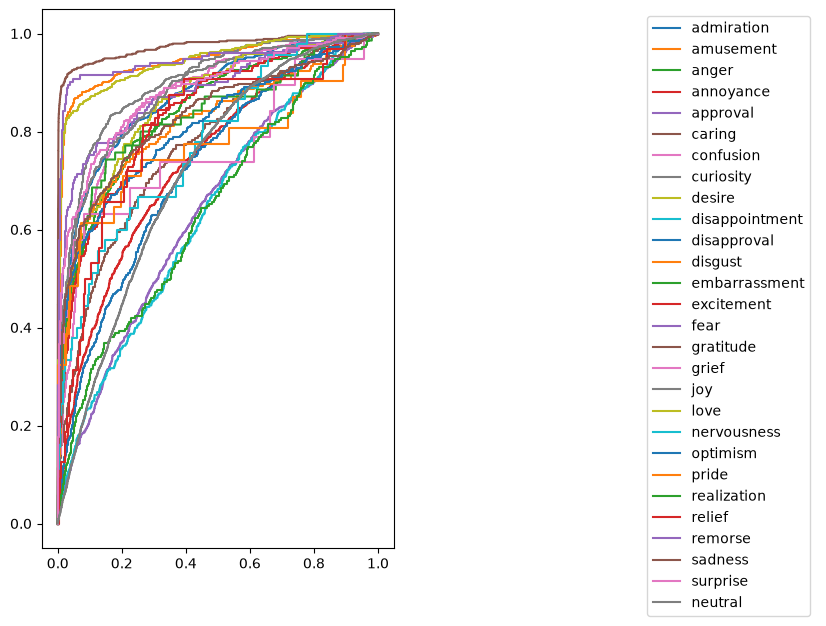

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(10, 7))

a, leg = plot_roc_curve(val_dataset, None, models[0], ax=ax[0], is_leg=True)
ax[1].axis('off')
ax[1].legend(*leg)

a

Plot the mean ROC AUC scores. Which model has the highest score? On what kind of dataset?

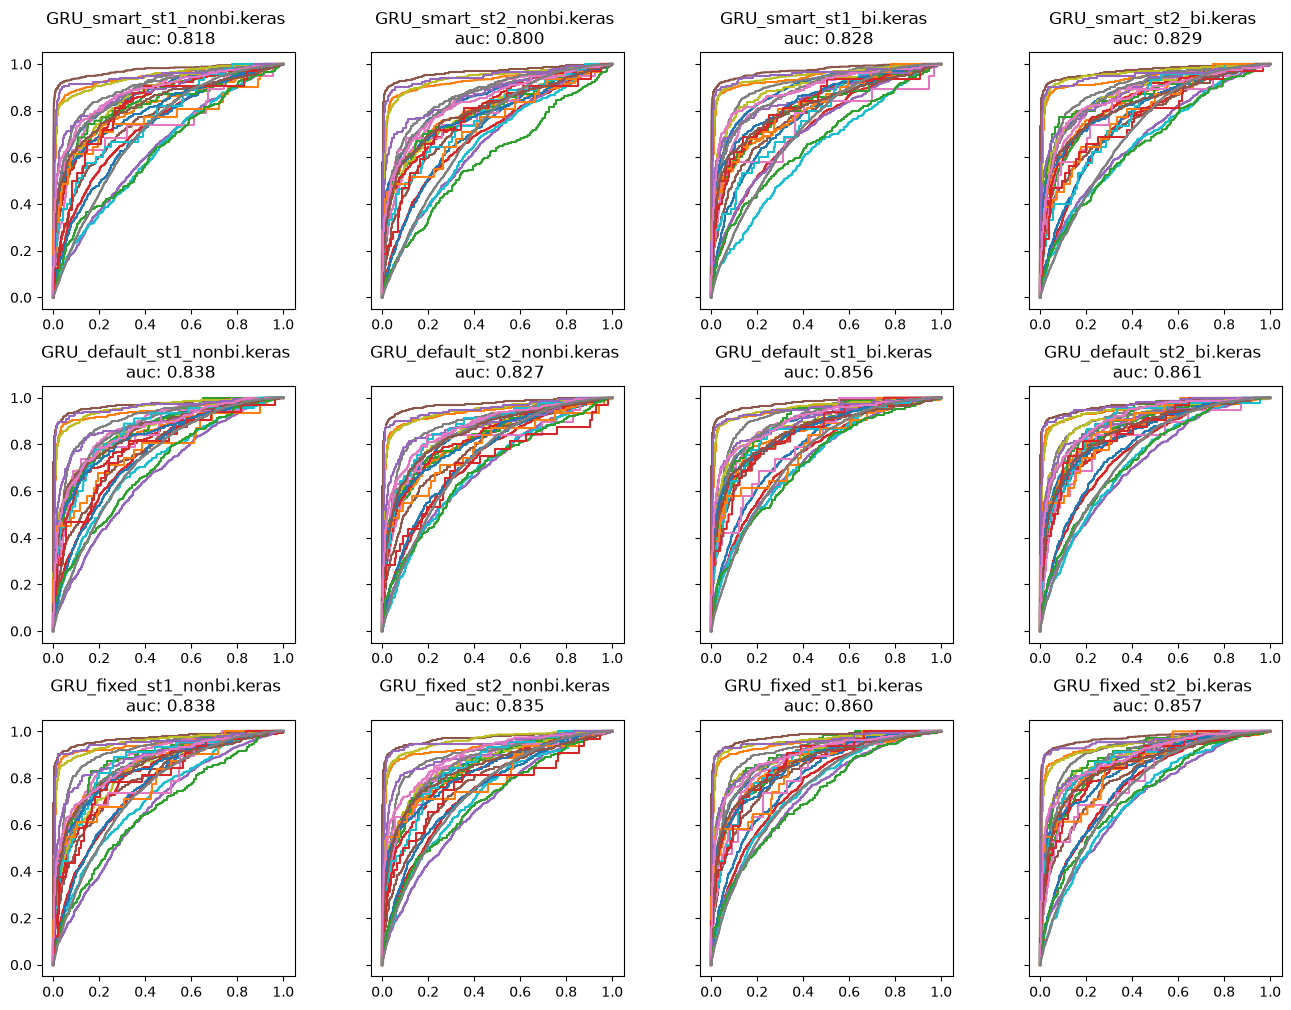

In [35]:
names = []
c = 0
for d in [smart_dataset, default_dataset, fixed_dataset]:
    for i in range(4):
        bi = 'bi' if (i // 2) % 2 == 1 else 'nonbi'
        st = 1 if i % 2 == 0 else 2
        d_type = dataset_type[c // 4]
        names.append(f'GRU_{d_type}_st{st}_{bi}.keras')
        c += 1

fig, axes = plt.subplots(3, 4, figsize=(16, 12), sharey=True)

for i in range(3):
    for j in range(4):
        score = plot_roc_curve(val_dataset, None, models[i * 4 + j], axes[i, j])
        axes[i, j].set_title(f'{names[i * 4 + j]} \n auc: {score:.3f}')

fig.subplots_adjust(hspace=0.3, wspace=0.3)

Inspect the best model performance closer. Come up with some sentences (in English). Does the model output sensible results?

In [36]:
def label_text(text: str, model: keras.Model, threshold: float = 0.5, max_length: int | None = None) -> list[str]:
    '''Computes the model output for `text` and outputs a list of emotions that have a probability of at least `threshold`

    Arguments:
        text: text to label
        model: model to use
        threshold: threshold to use
        max_length: max length for tokenization
    
    Return:
        List of predicted emotion labels'''

    tokens = np.array(tokenizer.encode(text, max_length=max_length), dtype='int32').reshape(1, -1)
    pred = np.array(keras.ops.convert_to_numpy(keras.ops.sigmoid(model(tokens)))).ravel()
    e = []

    for i, em in enumerate(emotions):
        if pred[i] >= threshold:
            e.append(em)

    return e


In [37]:
texts = [
    'This is the best thing I’ve seen all day. Thank you for sharing!',
    'I’m so sorry to hear that. Sending you strength.',
    'Honestly, I’m just tired of all this drama.',

    'Gravity is just a suggestion, and I politely decline.',
    'Please do not feed the concept of Tuesday.',

    'OMG THIS IS SO GOOOOD!!! I CANT EVEN!!!',
    'this is a simple text. I hate !!!!!!!. AAAAAAaaaAAAaAAAA. i want to eat. its fun',
    'y r u so madd?? i just asked lol',
    'bruh',

    'Kernel panic: my brain has stopped responding.',
    'sudo make me a sandwich',
    'rm -rf / --no-preserve-root',

    'Mamma mia, that’s a spicy meatball!',
    'She said ‘no’ but I heard ‘maybe’? Confusion.',

    '🔥🔥🔥 this is fire 🔥🔥🔥',
    '😭😭😭 my heart',
    '😡😡😡😡'
]

In [39]:
def plot_emotion_scores(text: str, model: keras.Model, max_length: int | None = None, ax: plt.Axes | None = None):
    '''Plots a bar plot of emotion probabilities for given `text` using `model`.

    Arguments:
        text: text to label
        model: model to use        
        max_length: max length for tokenization
        ax: axes to plot on'''
    tokens = np.array(tokenizer.encode(text, max_length=max_length), dtype='int32')[None]
    pred = keras.ops.convert_to_numpy(keras.ops.sigmoid(model(tokens))).ravel()

    ax.bar(emotions, pred)

For each of your texts get a list of emotion labels and plot emotion scores

/home/maks/HW/NLP/.venv/lib/python3.11/site-packages/IPython/core/events.py:101: UserWarning: Glyph 128293 (\N{FIRE}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
/home/maks/HW/NLP/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128293 (\N{FIRE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


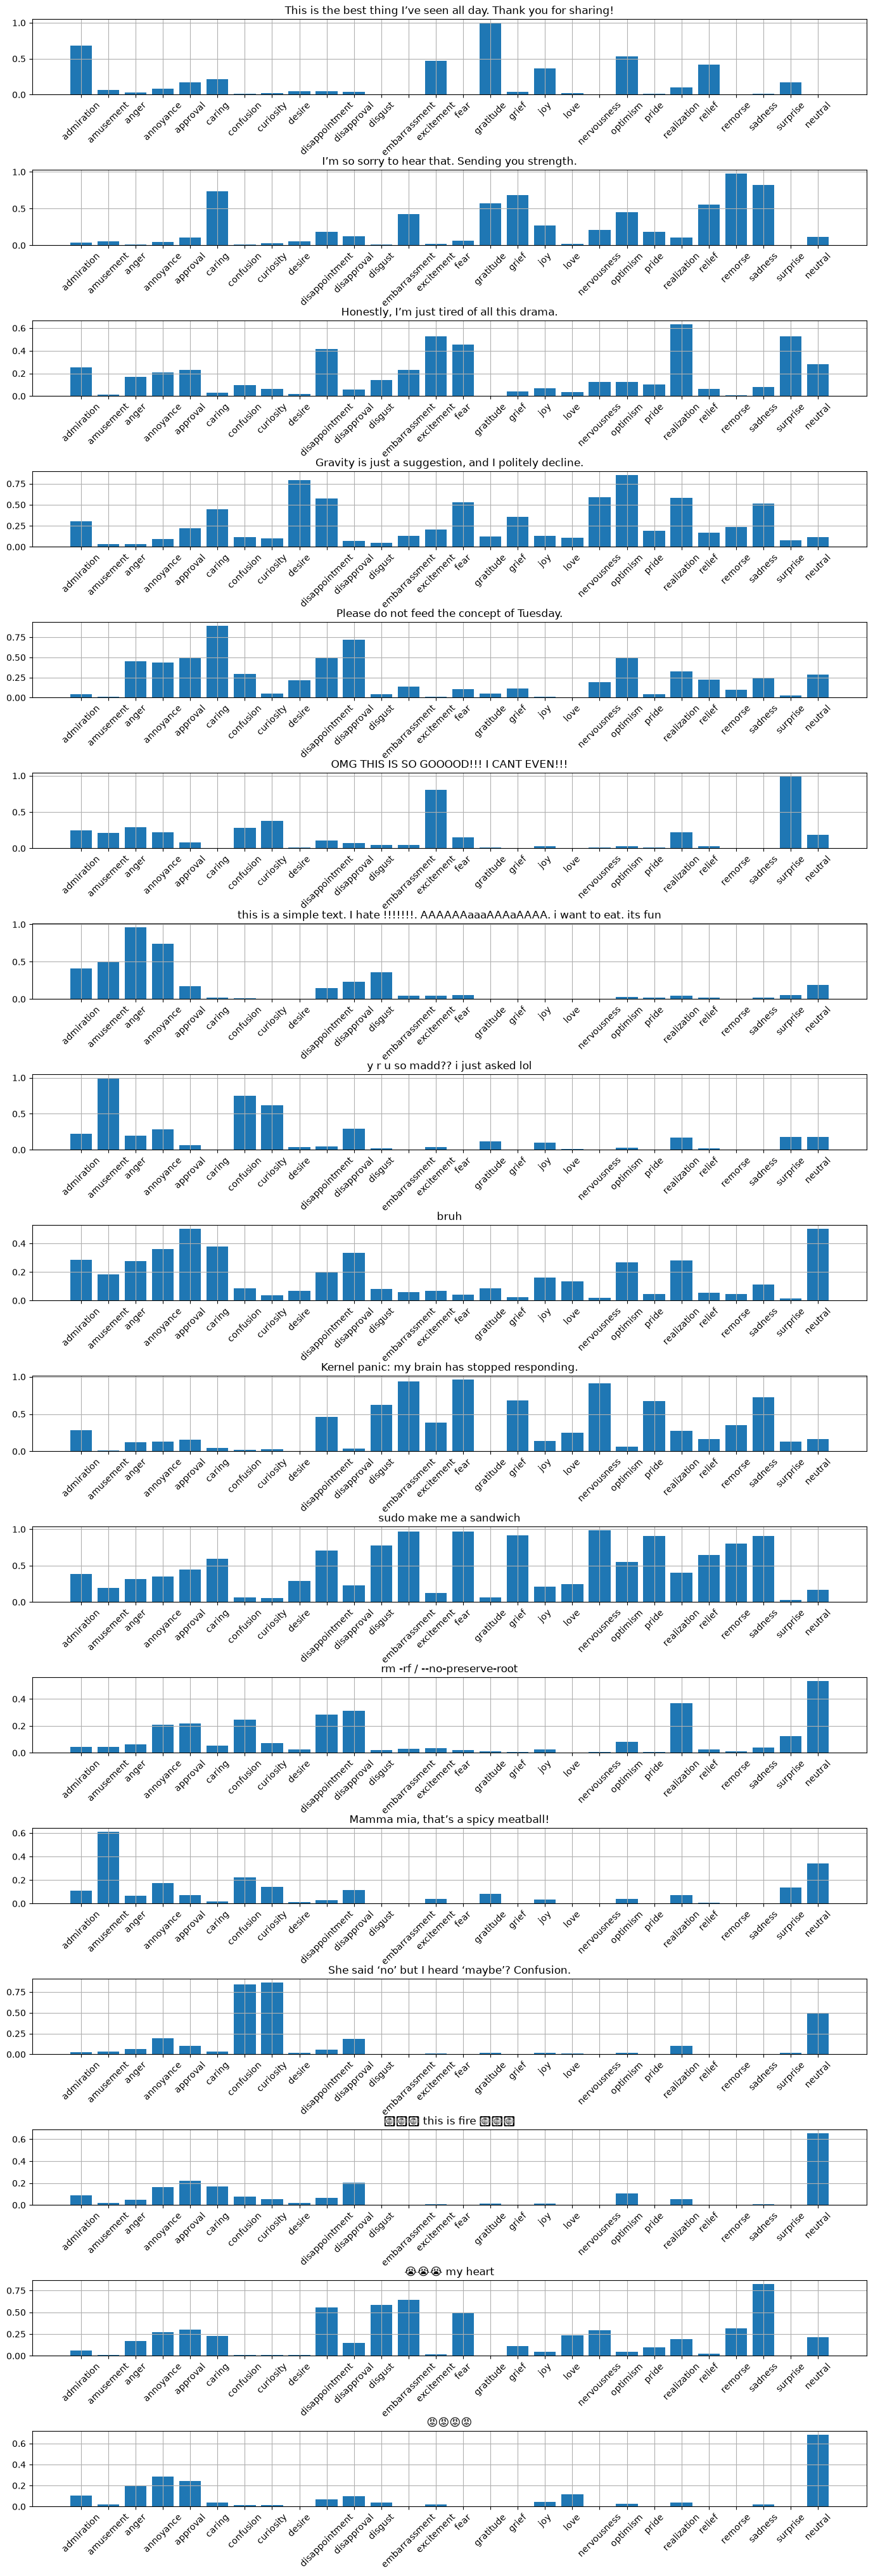

In [45]:
fig, ax = plt.subplots(len(texts), 1, figsize=(17, 3 * len(texts)))

for i, t in enumerate(texts):
    plot_emotion_scores(t, models[7], ax=ax[i])
    ax[i].tick_params(axis='x', rotation=45)
    ax[i].grid()
    ax[i].set_title(t)

fig.subplots_adjust(hspace=1)

# Bonus

Train and evaluate the same model as your best one, but use a different cell type

In [46]:
model_lstm = get_model(
    units=128,
    n_tokens=len(tokenizer.get_vocab()),
    n_labels=len(emotions),
    name='LSTM_model',
    bidirectional=True,
    n_stacks=2,
    cell_type=keras.layers.LSTMCell,
    embed_size=128
)

model_lstm.compile(
    loss=WeightedBCE(w, from_logits=True),
    optimizer=keras.optimizers.Adam(
        clipnorm=1.0
    ),
    metrics=[
        keras.metrics.AUC(multi_label=True, name='auc', num_labels=len(emotions)),
        keras.metrics.F1Score(average='macro', name='f1'),
    ]
)

In [119]:
model_lstm.fit(default_dataset, validation_data=val_dataset, epochs=20, callbacks=make_callbacks('LSTM_default_st2_bi'))

Epoch 1/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 91s 591ms/step - auc: 0.5116 - f1: 0.0389 - loss: 0.6867 - val_auc: 0.5350 - val_f1: 0.0359 - val_loss: 0.6423 - learning_rate: 0.0010
Epoch 2/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 84s 546ms/step - auc: 0.6001 - f1: 0.1010 - loss: 0.5879 - val_auc: 0.6438 - val_f1: 0.1538 - val_loss: 0.5531 - learning_rate: 0.0010
Epoch 3/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 85s 555ms/step - auc: 0.7181 - f1: 0.2251 - loss: 0.4712 - val_auc: 0.7131 - val_f1: 0.2338 - val_loss: 0.5086 - learning_rate: 0.0010
Epoch 4/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 86s 557ms/step - auc: 0.7907 - f1: 0.3209 - loss: 0.3870 - val_auc: 0.7183 - val_f1: 0.2671 - val_loss: 0.5134 - learning_rate: 0.0010
Epoch 5/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 87s 564ms/step - auc: 0.8329 - f1: 0.3938 - loss: 0.3320 - val_auc: 0.7301 - val_f1: 0.3031 - val_loss: 0.5407 - learning_rate: 0.0010
Epoch 6/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 85s 552ms/step - auc: 0.8605 - f1: 0.4460 - loss: 0.2906 - val_auc: 0.7471 - val_f1: 

In [47]:
model_lstm = keras.models.load_model('LSTM_default_st2_bi.keras')

0.8379654875869041


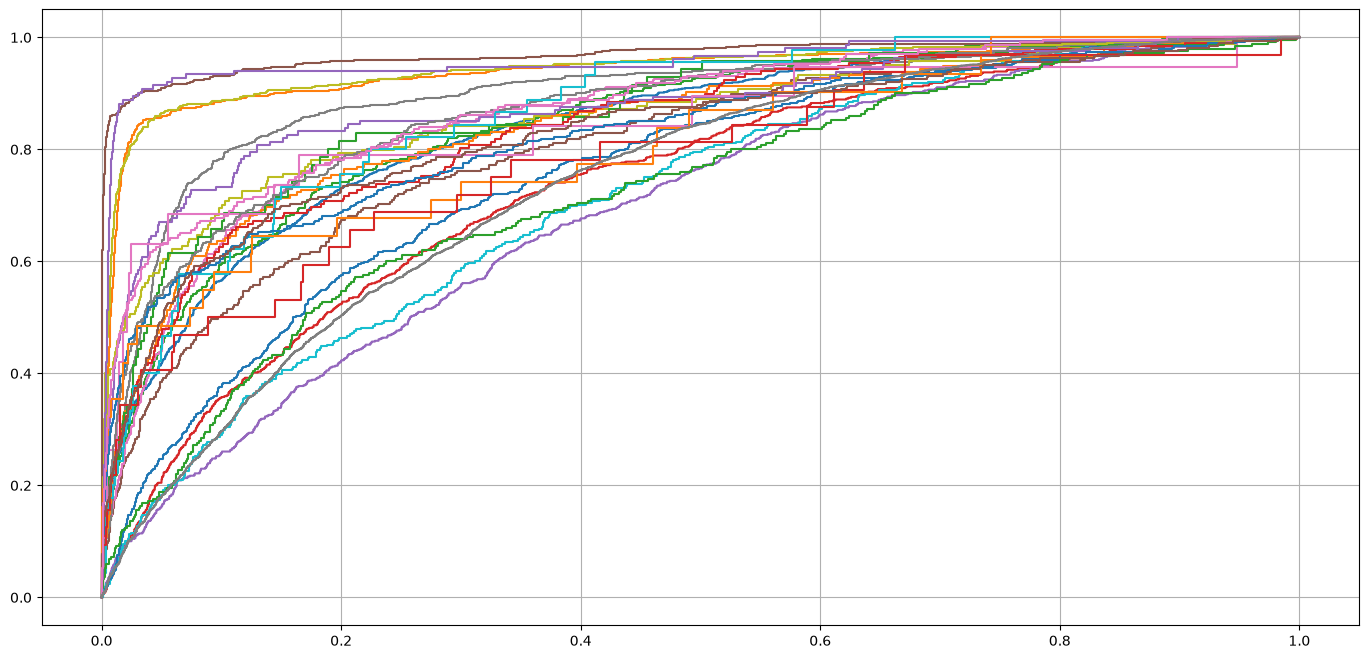

In [52]:
fig, ax = plt.subplots(1, 1, figsize=(17, 8))

# t = tokenizer.encode(texts[0])

print(plot_roc_curve(val_dataset, None, model_lstm, ax))
# plot_emotion_scores(texts[0], model_lstm, ax=ax[1])

# ax[1].tick_params(axis='x', rotation=45)
ax.grid()
# ax[1].grid()

/home/maks/HW/NLP/.venv/lib/python3.11/site-packages/IPython/core/events.py:101: UserWarning: Glyph 128293 (\N{FIRE}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
/home/maks/HW/NLP/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128293 (\N{FIRE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


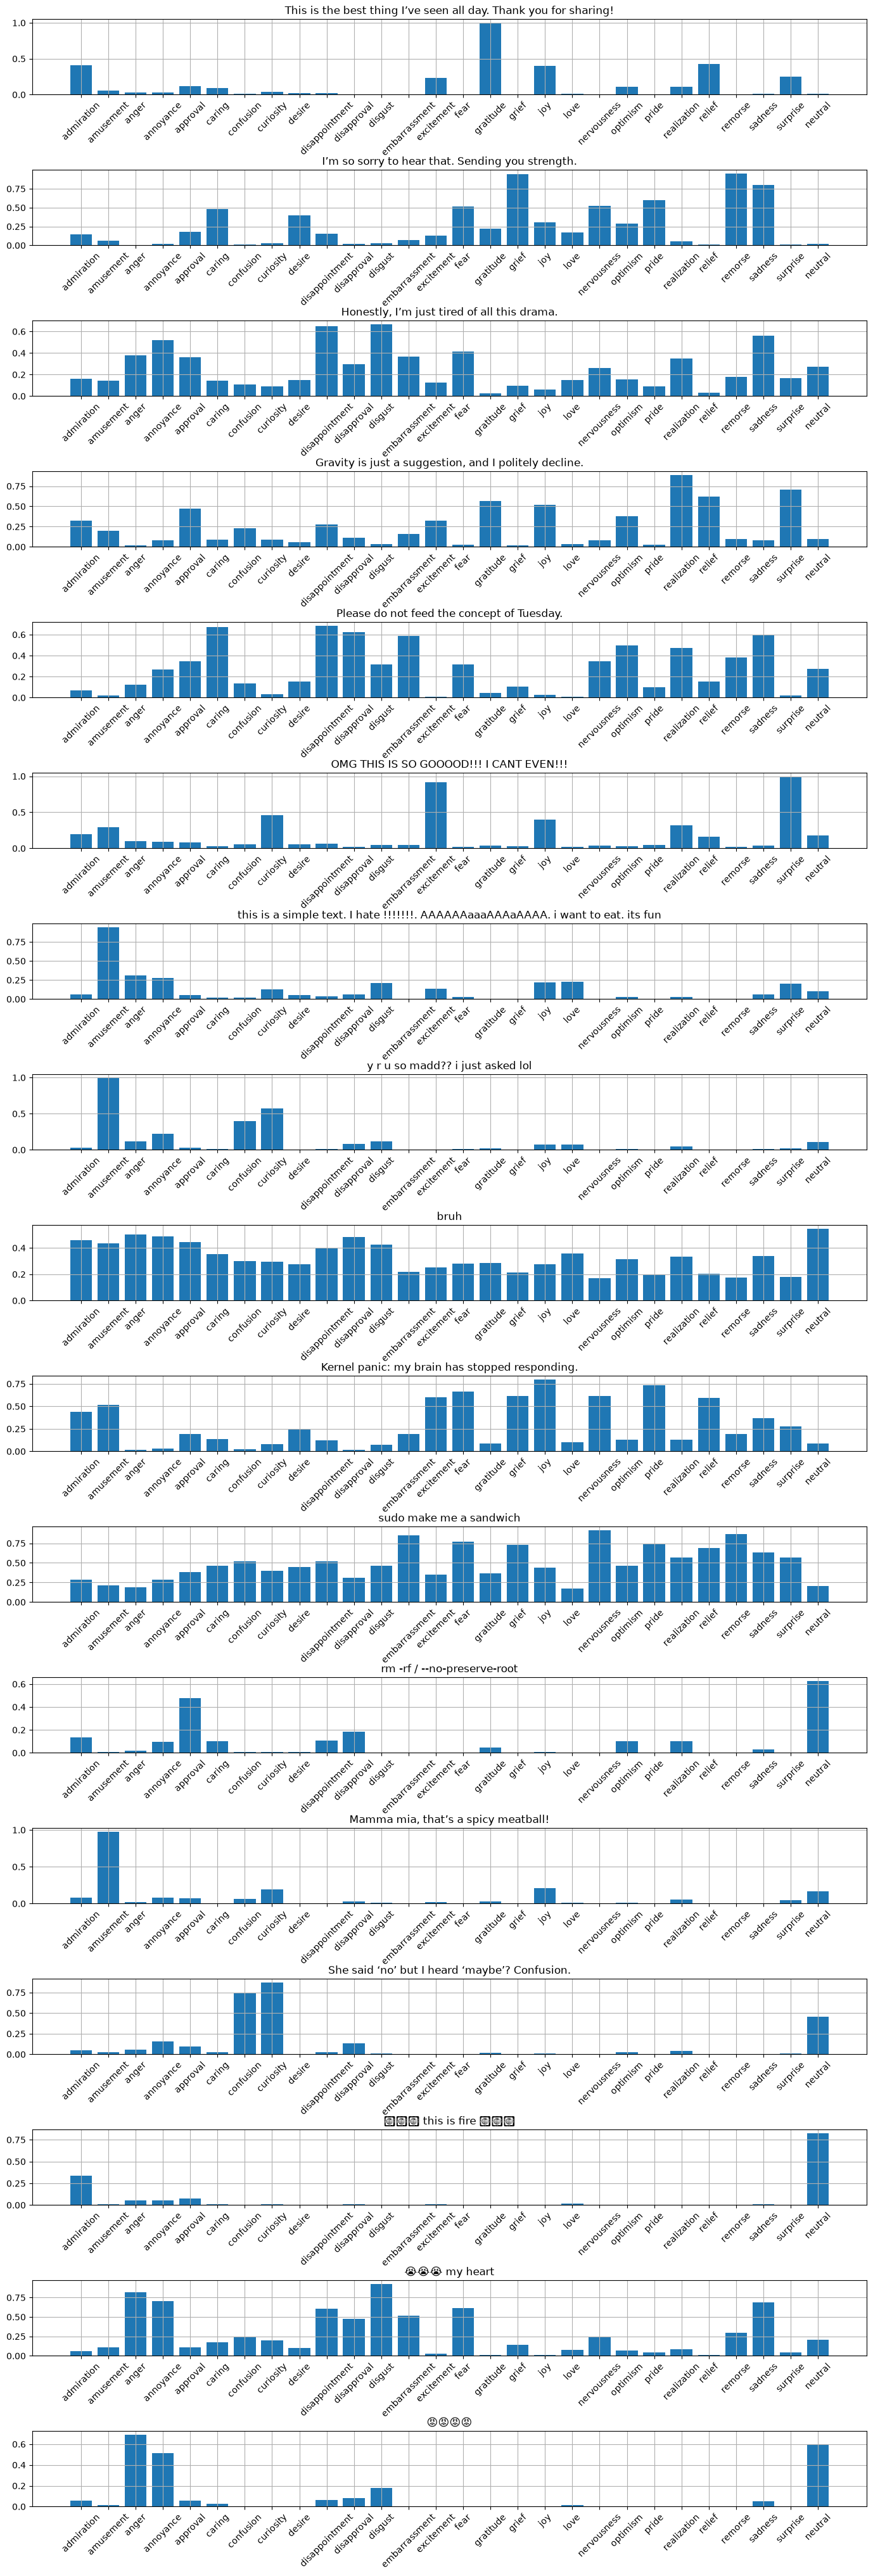

In [54]:
fig, ax = plt.subplots(len(texts), 1, figsize=(17, 3 * len(texts)))

for i, t in enumerate(texts):
    plot_emotion_scores(t, model_lstm, ax=ax[i])
    ax[i].tick_params(axis='x', rotation=45)
    ax[i].grid()
    ax[i].set_title(t)

fig.subplots_adjust(hspace=1)